## Cell 1 — Install libraries

In [20]:
%pip install torch torchvision numpy matplotlib scikit-learn pillow kagglehub

Note: you may need to restart the kernel to use updated packages.


## Cell 2 — Import libraries

In [21]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import kagglehub

import torch
import torch.nn as nn
import torch.optim as optim

from pathlib import Path
from PIL import Image
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Set seed for reproducibility
torch.manual_seed(42)
random.seed(42)
np.random.seed(42)

# Select GPU if available, otherwise CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


## Cell 3 — Download dataset

In [22]:
# Download Chest X-ray Pneumonia dataset from Kaggle
dataset_path = kagglehub.dataset_download(
    "paultimothymooney/chest-xray-pneumonia"
)

print("Downloaded dataset:", dataset_path)

Downloaded dataset: C:\Users\Kartik\.cache\kagglehub\datasets\paultimothymooney\chest-xray-pneumonia\versions\2


## Cell 4 — Verify dataset

In [23]:
# Locate the dataset folder
dataset_path = Path(dataset_path)

if (dataset_path / "chest_xray" / "train").exists():
    data_dir = dataset_path / "chest_xray"
else:
    data_dir = dataset_path

# Check image counts in each folder
for split in ["train", "val", "test"]:
    print(f"\n{split.upper()}")

    for category in ["NORMAL", "PNEUMONIA"]:
        folder = data_dir / split / category

        images = [
            file for file in folder.iterdir()
            if file.suffix.lower() in [".jpeg", ".jpg", ".png"]
        ]

        print(category, ":", len(images))


TRAIN
NORMAL : 1341
PNEUMONIA : 3875

VAL
NORMAL : 8
PNEUMONIA : 8

TEST
NORMAL : 234
PNEUMONIA : 390


## Cell 5 — Display sample images

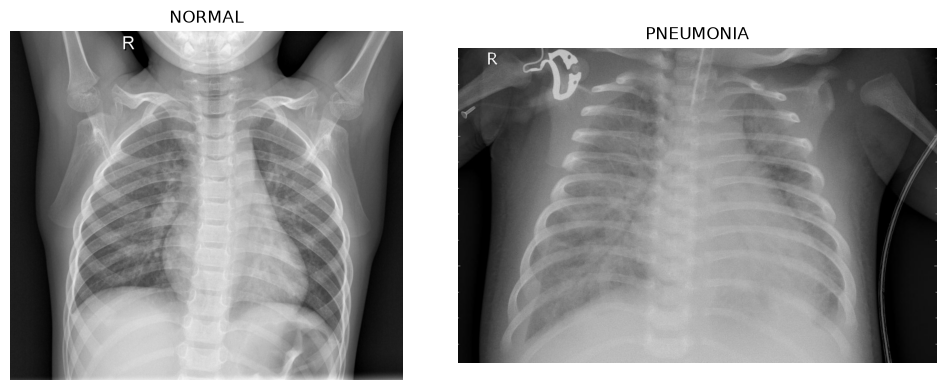

In [24]:
plt.figure(figsize=(10, 4))

for i, category in enumerate(["NORMAL", "PNEUMONIA"]):

    folder = data_dir / "train" / category

    image_path = next(
        file for file in folder.iterdir()
        if file.suffix.lower() in [".jpeg", ".jpg", ".png"]
    )

    image = Image.open(image_path).convert("RGB")

    plt.subplot(1, 2, i + 1)
    plt.imshow(image)
    plt.title(category)
    plt.axis("off")

plt.tight_layout()
plt.show()

## Cell 6 — Prepare image transformations

In [25]:
# Training images: resize, augment and normalize
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Validation and testing images: no random augmentation
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

## Cell 7 — Create datasets

In [26]:

from sklearn.model_selection import train_test_split
from torch.utils.data import Subset

train_path = data_dir / "train"
test_path = data_dir / "test"

# Load all original training images
full_dataset = datasets.ImageFolder(train_path)

# Create a larger, stratified validation split
train_indices, val_indices = train_test_split(
    np.arange(len(full_dataset)),
    test_size=0.20,
    random_state=42,
    stratify=full_dataset.targets
)

train_dataset = Subset(
    datasets.ImageFolder(train_path, transform=train_transform),
    train_indices
)

val_dataset = Subset(
    datasets.ImageFolder(train_path, transform=test_transform),
    val_indices
)

# Keep the original test set untouched
test_dataset = datasets.ImageFolder(
    test_path, transform=test_transform
)

class_names = full_dataset.classes

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))


Train: 4172
Validation: 1044
Test: 624


## Cell 8 — Create DataLoaders

In [27]:
batch_size = 16

# Training DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

# Validation DataLoader
val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

# Testing DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

# Check one batch
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

Image batch shape: torch.Size([16, 3, 224, 224])
Label batch shape: torch.Size([16])


## Cell 9 — Create DenseNet121 feature extractor

In [28]:
class DenseNetFeatureExtractor(nn.Module):

    def __init__(self):
        super().__init__()

        # Load pretrained DenseNet121
        densenet = models.densenet121(
            weights=models.DenseNet121_Weights.DEFAULT
        )

        # Keep CNN feature extraction layers
        self.features = densenet.features

    def forward(self, x):

        # Extract spatial features
        x = self.features(x)

        # Apply ReLU activation
        x = torch.relu(x)

        # Convert features into a sequence
        # (batch, 1024, 7, 7) -> (batch, 49, 1024)
        x = x.flatten(2).transpose(1, 2)

        return x

## Cell 10 — Create BiLSTM model

In [29]:
class BiLSTMModel(nn.Module):

    def __init__(self):
        super().__init__()

        # Bidirectional LSTM
        self.lstm = nn.LSTM(
            input_size=1024,
            hidden_size=128,
            num_layers=1,
            batch_first=True,
            bidirectional=True
        )

    def forward(self, x):

        # Process the sequence of CNN features
        x, _ = self.lstm(x)

        # Average across all sequence positions
        x = x.mean(dim=1)

        return x

## Cell 11 — Create hybrid model

In [30]:
class HybridModel(nn.Module):

    def __init__(self):
        super().__init__()

        # DenseNet121 feature extractor
        self.cnn = DenseNetFeatureExtractor()

        # BiLSTM feature processor
        self.bilstm = BiLSTMModel()

        # Fully Connected classification layer
        self.fc = nn.Linear(256, 2)

    def forward(self, x):

        # Extract CNN features
        x = self.cnn(x)

        # Process features using BiLSTM
        x = self.bilstm(x)

        # Classify as Normal or Pneumonia
        x = self.fc(x)

        return x


# Initialize the model
model = HybridModel().to(device)

print("Hybrid model created successfully!")

Hybrid model created successfully!


## Cell 12 — Define loss function and optimizer

In [31]:

# Initialize a fresh model after changing the split
model = HybridModel().to(device)

# Calculate class weights from training images only
train_labels = np.array(full_dataset.targets)[train_indices]
counts = np.bincount(train_labels, minlength=2)

class_weights = torch.tensor(
    counts.sum() / (2 * counts),
    dtype=torch.float32,
    device=device
)

# Weighted classification loss
criterion = nn.CrossEntropyLoss(weight=class_weights)

# Different learning rates for CNN and classifier
optimizer = optim.AdamW([
    {"params": model.cnn.parameters(), "lr": 1e-5},
    {"params": list(model.bilstm.parameters()) +
               list(model.fc.parameters()), "lr": 1e-4}
], weight_decay=1e-4)

# Learning rate scheduler
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=2
)

epochs = 20
early_stopping_patience = 5


## Cell 13 — Train and validate model

In [32]:

# Cell 13 — Train and Validate Hybrid Model

# Store training history
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

# Best model settings
best_val_loss = float("inf")
patience_counter = 0
best_model_path = "best_model.pth"

for epoch in range(epochs):

    # ---------- TRAINING ----------
    model.train()

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward propagation
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update model weights
        optimizer.step()

        # Calculate training statistics
        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    # ---------- VALIDATION ----------
    model.eval()

    val_loss_sum = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            # Forward propagation
            outputs = model(images)

            # Calculate validation loss
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)

            # Calculate validation accuracy
            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    # ---------- STORE RESULTS ----------
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    # Display results
    print(
        f"Epoch [{epoch+1}/{epochs}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    # ---------- LEARNING RATE SCHEDULER ----------
    scheduler.step(val_loss)

    # ---------- SAVE BEST MODEL ----------
    if val_loss < best_val_loss - 1e-4:

        best_val_loss = val_loss
        patience_counter = 0

        torch.save(model.state_dict(), best_model_path)

        print("Best model saved!")

    else:
        patience_counter += 1

    # ---------- EARLY STOPPING ----------
    if patience_counter >= early_stopping_patience:

        print("Early stopping activated!")
        break


# ---------- LOAD BEST MODEL ----------
model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device,
        weights_only=True
    )
)

model.eval()

print("Training completed!")
print("Best model loaded successfully!")
print(f"Best Validation Loss: {best_val_loss:.4f}")


Epoch [1/20] | Train Loss: 0.2439 | Train Acc: 0.9255 | Val Loss: 0.1056 | Val Acc: 0.9550
Best model saved!
Epoch [2/20] | Train Loss: 0.0941 | Train Acc: 0.9655 | Val Loss: 0.0759 | Val Acc: 0.9761
Best model saved!
Epoch [3/20] | Train Loss: 0.0708 | Train Acc: 0.9744 | Val Loss: 0.0677 | Val Acc: 0.9741
Best model saved!
Epoch [4/20] | Train Loss: 0.0561 | Train Acc: 0.9827 | Val Loss: 0.0943 | Val Acc: 0.9531
Epoch [5/20] | Train Loss: 0.0479 | Train Acc: 0.9827 | Val Loss: 0.0681 | Val Acc: 0.9684
Epoch [6/20] | Train Loss: 0.0372 | Train Acc: 0.9861 | Val Loss: 0.0605 | Val Acc: 0.9799
Best model saved!
Epoch [7/20] | Train Loss: 0.0299 | Train Acc: 0.9892 | Val Loss: 0.0636 | Val Acc: 0.9780
Epoch [8/20] | Train Loss: 0.0335 | Train Acc: 0.9902 | Val Loss: 0.0764 | Val Acc: 0.9703
Epoch [9/20] | Train Loss: 0.0229 | Train Acc: 0.9916 | Val Loss: 0.0711 | Val Acc: 0.9751
Epoch [10/20] | Train Loss: 0.0167 | Train Acc: 0.9942 | Val Loss: 0.0625 | Val Acc: 0.9828
Epoch [11/20] | T

## Cell 14 — Plot training results

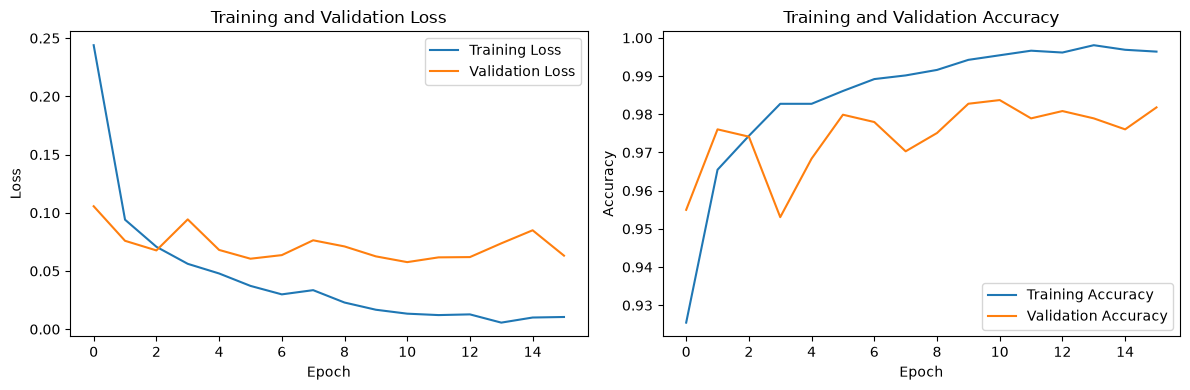

In [33]:
plt.figure(figsize=(12, 4))

# Loss graph
plt.subplot(1, 2, 1)

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()

# Accuracy graph
plt.subplot(1, 2, 2)

plt.plot(train_accuracies, label="Training Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

## Cell 15 — Test the model

In [34]:
model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        # Predict classes
        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

# Calculate test accuracy
accuracy = np.mean(
    np.array(all_predictions) == np.array(all_labels)
)

print(f"Test Accuracy: {accuracy * 100:.2f}%")

# Precision, recall and F1-score
print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=class_names,
        zero_division=0
    )
)

Test Accuracy: 83.17%
              precision    recall  f1-score   support

      NORMAL       0.99      0.56      0.71       234
   PNEUMONIA       0.79      1.00      0.88       390

    accuracy                           0.83       624
   macro avg       0.89      0.78      0.80       624
weighted avg       0.87      0.83      0.82       624



## Cell 16 — Confusion matrix

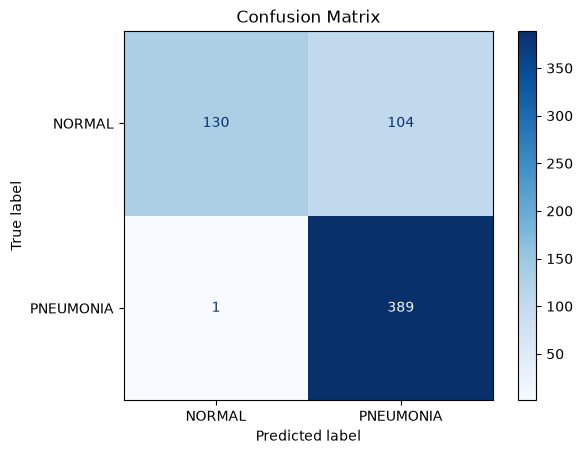

In [35]:
cm = confusion_matrix(all_labels, all_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

## Cell 17 — Save trained model

In [36]:
torch.save(
    model.state_dict(),
    "pneumonia_hybrid_model.pth"
)

print("Model saved successfully!")

Model saved successfully!


## Cell 18 — Predict a new chest X-ray

In [37]:
def predict_pneumonia(image_path):

    image = Image.open(image_path).convert("RGB")

    image_tensor = test_transform(image).unsqueeze(0)
    image_tensor = image_tensor.to(device)

    model.eval()

    with torch.no_grad():

        output = model(image_tensor)

        probabilities = torch.softmax(output, dim=1)

        predicted_class = probabilities.argmax(dim=1).item()

    print("Prediction:", class_names[predicted_class])

    for i, class_name in enumerate(class_names):
        print(f"{class_name}: {probabilities[0][i].item() * 100:.2f}%")

    plt.imshow(image)
    plt.title(class_names[predicted_class])
    plt.axis("off")
    plt.show()